# Paraphrase detection on PAWS-Wiki: BPE tokenizer, bag-of-words representations, logistic regression and MLPs

Notebook with all the experiments of the project. 

Sections: 
- tokenizer (1-3)
- representation spaces (4)
- cross-validation setup (5)
- logistic regression (6)
- one-hidden-layer MLP (7)
- deeper MLP (8)
- evaluation with a Bayesian comparison (9)
- final test evaluation with error analysis (10)
All models are compared on the same 5 cross-validation folds; the test set is used only once, at the end.


In [1]:
import os
import warnings

# Hide warnings (sklearn convergence, torch sparse tensors, etc.) to keep the outputs clean.
warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"


## 1. Training the tokenizer

Our classifier needs a way to segment text into tokens. We train a **Byte-Pair Encoding (BPE)** tokenizer on the PAWS training set.

BPE starts from single characters and repeatedly merges the most frequent pair of symbols until it reaches the target vocabulary size. Frequent words end up as a single token, while rare words (e.g. names) are split into sub-word pieces, so we almost never need an `[UNK]` token.

We decided to train our own tokanizer since a pre-trained tokenizer carries the vocabulary of the corpus it was trained on. PAWS-Wiki is made of Wikipedia sentences (many names, places and biography terms), so a vocabulary learned on these sentences keep frequent words as a single tokens, while a generic one would split more of them. Training it outselves also let us choose the vocabulary size, which controls how many features the classifiers receive. 

**Training data.** We use both sentences of every pair in the **train** split only (98,802 sentences), so no information from validation or test leaks into the tokenizer. PAWS is built from Wikipedia, so it is large enough for a vocabulary of this size.

In [2]:
from src.dataset import load_paws, tokenizer_corpus
from src.tokenization import train_tokenizer

dataset = load_paws()
corpus = tokenizer_corpus(dataset)   # train only, sentence1 + sentence2
print(f"{len(corpus):,} sentences in the tokenizer corpus")

Removed 63 examples from 31 conflicting pairs.
Training examples remaining: 49,338
98,676 sentences in the tokenizer corpus


## 2. Choosing the hyperparameters

Two hyperparameters:
- `vocab_size`: number of tokens in the vocabulary.
- `min_frequency`: a pair of symbols is only merged if it appears at least this many times.

We train several tokenizers and measure, on the **validation** sentences (unseen during training):
- `avg_tokens_per_sentence`: fewer tokens means the vocabulary groups more characters per token.
- `unk_rate`: fraction of tokens that are `[UNK]`. Close to 0 means the tokenizer covers new text.

Larger vocabularies give shorter sequences but sparser features, since many tokens appear only a few times.

In [3]:
import pandas as pd
from src.tokenization import tokenizer_stats

val_texts = list(dataset["validation"]["sentence1"]) + list(dataset["validation"]["sentence2"])

# Train each tokenizer once and keep it, so the following cells can reuse it
tokenizers = {}
rows = []
for vocab_size in [1000, 4000, 8000]:
    for min_freq in [2, 5]:
        tokenizers[(vocab_size, min_freq)] = train_tokenizer(corpus, vocab_size, min_freq)
        rows.append({"min_frequency": min_freq, **tokenizer_stats(tokenizers[(vocab_size, min_freq)], val_texts)})
pd.DataFrame(rows)

,min_frequency,vocab_size,avg_tokens_per_sentence,unk_rate
0,2,1000,44.898125,0.000063
1,5,1000,44.898125,0.000063
2,2,4000,33.070750,0.000085
3,5,4000,33.070750,0.000085
4,2,8000,29.212563,0.000096
5,5,8000,29.212563,0.000096


**Observations.**
- `min_frequency` has **no effect** here (2 and 5 give identical rows): with these vocabulary sizes every merge already appears far more than 5 times, so the filter never applies and training stops when `vocab_size` is reached. We keep `min_frequency=2`, as in the tutorial.
- `vocab_size` matters: going from 1,000 (the tutorial's value) to 4,000 shortens sentences considerably (≈45 → ≈33 tokens), and 8,000 gives a smaller further gain (≈29).
- `[UNK]` is practically zero in all cases (<0.02%), so coverage is not a differentiating factor.

These statistics only describe the tokenizers; they do not tell us which one classifies best. That is decided later with the classifier's validation accuracy.

### 2.1. Inspecting how sentences are tokenized

The table above averages over the whole validation set. To see *how* text is actually split, we look at three validation sentences with each vocabulary size. `▁` marks the start of a word. We look for: are frequent words kept whole? Are rare words (names) split into meaningful pieces or into single characters?

In [4]:
for i in [0, 5, 10]:
    sentence = dataset["validation"][i]["sentence1"]
    print(sentence)
    for vocab_size in [1000, 4000, 8000]:
        tokens = tokenizers[(vocab_size, 2)].encode(sentence).tokens
        print(f"  vocab={vocab_size:>5} ({len(tokens):>2} tokens): {' '.join(tokens)}")
    print()

Bradd Crellin represented BARLA Cumbria on a tour of Australia with 6 other players representing Britain , also on a tour of Australia .
  vocab= 1000 (48 tokens): ▁B rad d ▁C re l lin ▁rep resent ed ▁B A R L A ▁C um b ri a ▁on ▁a ▁t our ▁of ▁Austral ia ▁with ▁6 ▁other ▁play ers ▁rep resent ing ▁B rit ain ▁, ▁also ▁on ▁a ▁t our ▁of ▁Austral ia ▁.
  vocab= 4000 (35 tokens): ▁Brad d ▁C re l lin ▁represented ▁B A R L A ▁C umb ria ▁on ▁a ▁tour ▁of ▁Australia ▁with ▁6 ▁other ▁players ▁represent ing ▁Britain ▁, ▁also ▁on ▁a ▁tour ▁of ▁Australia ▁.
  vocab= 8000 (33 tokens): ▁Brad d ▁Cre l lin ▁represented ▁B A R LA ▁C umb ria ▁on ▁a ▁tour ▁of ▁Australia ▁with ▁6 ▁other ▁players ▁represent ing ▁Britain ▁, ▁also ▁on ▁a ▁tour ▁of ▁Australia ▁.

Kathy and her husband Pete Beale ( Peter Dean ) are stable financially .
  vocab= 1000 (30 tokens): ▁K ath y ▁and ▁her ▁h us b and ▁P et e ▁Be ale ▁( ▁P eter ▁De an ▁) ▁are ▁st able ▁f in an c ial ly ▁.
  vocab= 4000 (21 tokens): ▁Kath y ▁and ▁her ▁husba

**Case study: *financially*.** With 1,000 tokens the word is cut into 6 pieces (`f in an c ial ly`), most of them generic fragments that appear inside thousands of unrelated words, so each feature says little about the word. With 4,000 tokens it needs 3 pieces, and with 8,000 only 2 (`financ ially`): a meaningful stem and a common suffix. The related word *financial* (114 occurrences in the training sentences) becomes a single token at 8,000, so the classifier gets a specific feature for it instead of a combination of fragments. 

## 3. Final tokenizer

In [ ]:
final_vocab_size = 8000  
tokenizer = tokenizers[(final_vocab_size, 2)]
tokenizer.save(f"tokenizer_bpe_{final_vocab_size}.json")
print("vocabulary size:", tokenizer.get_vocab_size())

vocabulary size: 8000


### 3.1. Example

A sentence from the validation set, split into BPE tokens. `▁` marks the start of a word. Frequent words stay whole, rare names are split into pieces.

In [6]:
example = dataset["validation"][0]["sentence1"]
print(example)
print(tokenizer.encode(example).tokens)

Bradd Crellin represented BARLA Cumbria on a tour of Australia with 6 other players representing Britain , also on a tour of Australia .
['▁Brad', 'd', '▁Cre', 'l', 'lin', '▁represented', '▁B', 'A', 'R', 'LA', '▁C', 'umb', 'ria', '▁on', '▁a', '▁tour', '▁of', '▁Australia', '▁with', '▁6', '▁other', '▁players', '▁represent', 'ing', '▁Britain', '▁,', '▁also', '▁on', '▁a', '▁tour', '▁of', '▁Australia', '▁.']


### Jaccard similarity analysis

The following code calculates the Jaccard similarity of the paraphrasing and non-paraphasing sentences of the dataset using an increasing group of tokens of them. After that, it calculates the mean value of the two distributions formed for every fixed group of tokens and substract them.

This allows us to analyze which is the optimal number of tokens we can group the sentences to obtain the maximum distinguishability between the paraphrasing and non-paraphrasing sentences, for later using it on the frequency N-gram enconder model. 


Analyzing BPE vocabulary: 8000


,vocab_size,n,mean_non_para,mean_para,mean_dist,cohens_d,pct_empty_pairs
0,8000,1,0.8597,0.8572,0.0025,0.0259,0.0000
1,8000,2,0.5533,0.6371,0.0839,0.5726,0.0000
2,8000,3,0.3847,0.5143,0.1295,0.8027,0.0000
3,8000,4,0.2752,0.4247,0.1495,0.8952,0.0000
4,8000,5,0.2023,0.3564,0.1541,0.9202,0.0000
5,8000,6,0.1521,0.3020,0.1500,0.9058,0.0000
6,8000,7,0.1164,0.2581,0.1417,0.8741,0.0041
7,8000,8,0.0903,0.2217,0.1314,0.8330,0.0081
8,8000,9,0.0706,0.1910,0.1204,0.7874,0.0263
9,8000,10,0.0555,0.1648,0.1093,0.7400,0.0993



Optimal n-gram size for each BPE vocabulary:


,vocab_size,best_n_mean_dist,best_mean_dist,best_n_cohens_d,best_cohens_d
0,8000,5,0.1541,5,0.9202


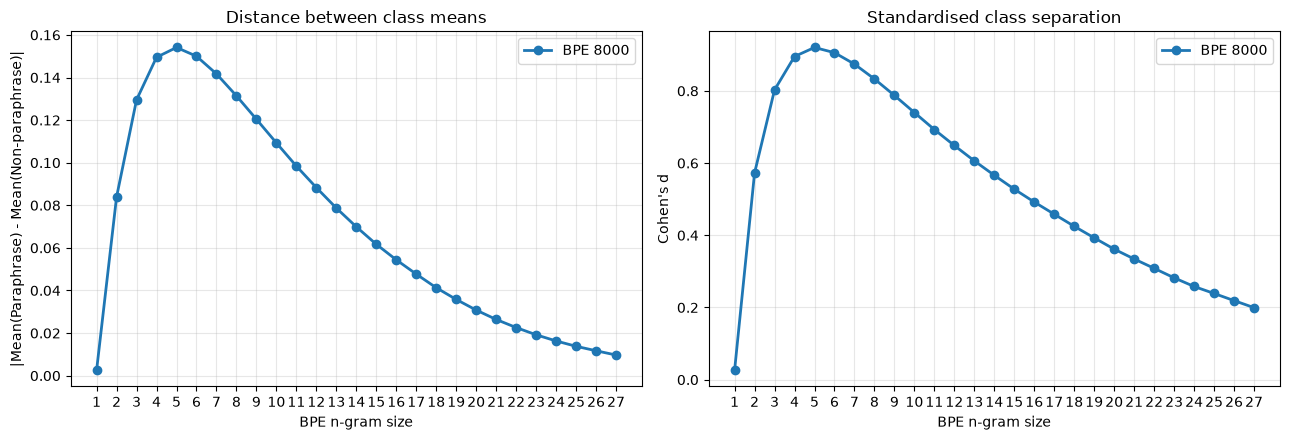

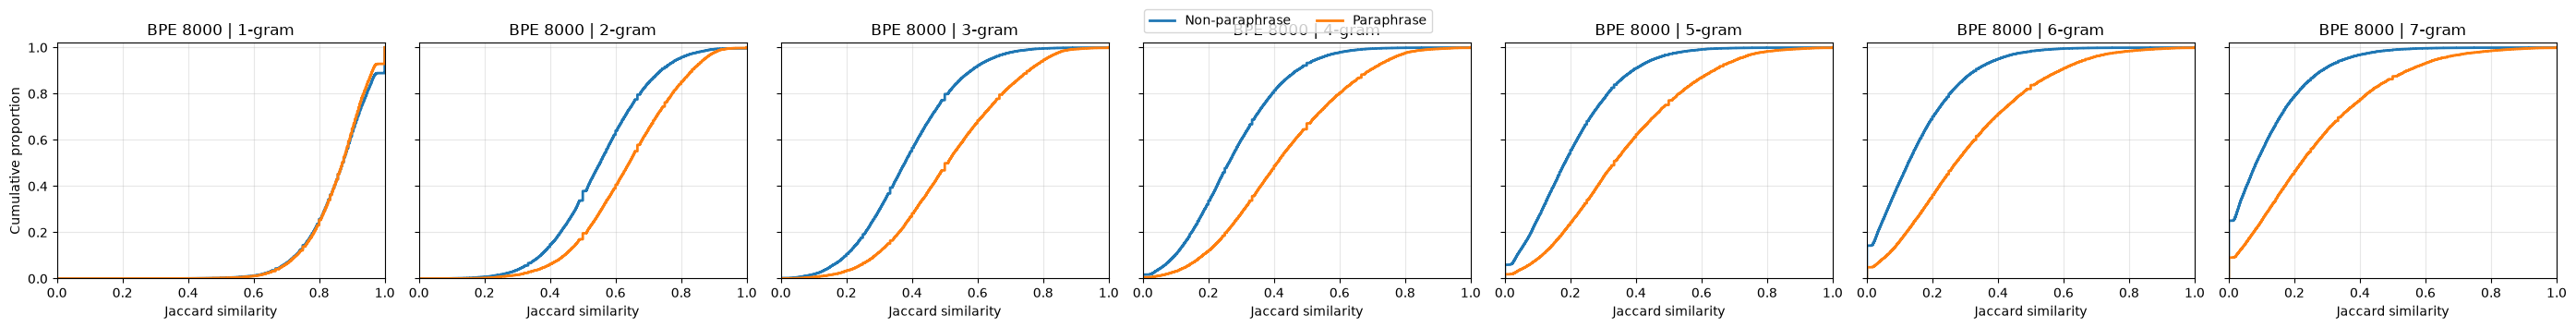

In [7]:
# ============================================================
# BPE-BASED JACCARD ANALYSIS
# Compare n-gram Jaccard across different BPE vocabulary sizes
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("images", exist_ok=True)   # the figures below are saved here

# -------------------- PARAMETERS --------------------

VOCAB_SIZES = [8000]
MIN_FREQ = 2
MAX_N = 27
MAX_PLOT_N = 7

# Use the original training split, as in data_exploration
train_df_bpe = dataset["train"].to_pandas()

labels = train_df_bpe["label"].to_numpy()

# -------------------- HELPER FUNCTIONS --------------------

def bpe_ngram_set(tokens, n):
    """Extract unique consecutive BPE n-grams."""
    return {
        tuple(tokens[i:i+n])
        for i in range(len(tokens) - n + 1)
    }


def bpe_jaccard(a, b):
    """Calculate Jaccard similarity between two sets."""
    union = len(a | b)
    return len(a & b) / union if union else 0.0


def cohens_d(x0, x1):
    """Calculate absolute Cohen's d using pooled standard deviation."""
    n0, n1 = len(x0), len(x1)

    pooled_std = np.sqrt(
        (
            (n0 - 1) * x0.var(ddof=1)
            + (n1 - 1) * x1.var(ddof=1)
        ) / (n0 + n1 - 2)
    )

    return abs(x1.mean() - x0.mean()) / pooled_std if pooled_std > 0 else 0.0


# -------------------- MAIN ANALYSIS --------------------

bpe_results = {}
summary_rows = []

for vocab_size in VOCAB_SIZES:

    print(f"\nAnalyzing BPE vocabulary: {vocab_size}")

    # Retrieve the previously trained tokenizer
    bpe_tokenizer = tokenizers[(vocab_size, MIN_FREQ)]

    # Tokenize both sentences using BPE
    tokens1 = [
        bpe_tokenizer.encode(text).tokens
        for text in train_df_bpe["sentence1"]
    ]

    tokens2 = [
        bpe_tokenizer.encode(text).tokens
        for text in train_df_bpe["sentence2"]
    ]

    results_by_n = {}

    for n in range(1, MAX_N + 1):

        # Generate BPE n-gram sets
        sets1 = [bpe_ngram_set(t, n) for t in tokens1]
        sets2 = [bpe_ngram_set(t, n) for t in tokens2]

        # Calculate Jaccard for every sentence pair
        jac = np.array([
            bpe_jaccard(a, b)
            for a, b in zip(sets1, sets2)
        ])

        # Separate classes
        j0 = jac[labels == 0]
        j1 = jac[labels == 1]

        mean_dist = abs(j1.mean() - j0.mean())

        # Store results
        results_by_n[n] = jac

        summary_rows.append({
            "vocab_size": vocab_size,
            "n": n,
            "mean_non_para": j0.mean(),
            "mean_para": j1.mean(),
            "mean_dist": mean_dist,
            "cohens_d": cohens_d(j0, j1),
            "pct_empty_pairs": 100 * np.mean([
                not (a or b)
                for a, b in zip(sets1, sets2)
            ])
        })

    bpe_results[vocab_size] = results_by_n


# -------------------- RESULTS TABLE --------------------

bpe_summary = pd.DataFrame(summary_rows).round(4)

display(bpe_summary)


# -------------------- OPTIMAL N FOR EACH VOCABULARY --------------------

optimal_rows = []

for vocab_size in VOCAB_SIZES:

    subset = bpe_summary[
        bpe_summary["vocab_size"] == vocab_size
    ]

    best_dist = subset.loc[subset["mean_dist"].idxmax()]
    best_d = subset.loc[subset["cohens_d"].idxmax()]

    optimal_rows.append({
        "vocab_size": vocab_size,
        "best_n_mean_dist": int(best_dist["n"]),
        "best_mean_dist": best_dist["mean_dist"],
        "best_n_cohens_d": int(best_d["n"]),
        "best_cohens_d": best_d["cohens_d"]
    })

optimal_summary = pd.DataFrame(optimal_rows).round(4)

print("\nOptimal n-gram size for each BPE vocabulary:")
display(optimal_summary)


# -------------------- PLOT 1: METRIC COMPARISON --------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4.5)
)

for vocab_size in VOCAB_SIZES:

    subset = bpe_summary[
        bpe_summary["vocab_size"] == vocab_size
    ]

    axes[0].plot(
        subset["n"],
        subset["mean_dist"],
        marker="o",
        linewidth=2,
        label=f"BPE {vocab_size}"
    )

    axes[1].plot(
        subset["n"],
        subset["cohens_d"],
        marker="o",
        linewidth=2,
        label=f"BPE {vocab_size}"
    )

axes[0].set_title("Distance between class means")
axes[0].set_xlabel("BPE n-gram size")
axes[0].set_ylabel(
    "|Mean(Paraphrase) - Mean(Non-paraphrase)|"
)

axes[1].set_title("Standardised class separation")
axes[1].set_xlabel("BPE n-gram size")
axes[1].set_ylabel("Cohen's d")

for ax in axes:
    ax.set_xticks(range(1, MAX_N + 1))
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig("images/bpe_jaccard_metrics.png", dpi=300, bbox_inches="tight")
plt.show()


# -------------------- PLOT 2: CUMULATIVE DISTRIBUTIONS --------------------

fig, axes = plt.subplots(
    len(VOCAB_SIZES),
    MAX_PLOT_N,
    figsize=(4 * MAX_PLOT_N, 3.5 * len(VOCAB_SIZES)),
    sharex=True,
    sharey=True,
    squeeze=False
)

for row, vocab_size in enumerate(VOCAB_SIZES):

    for col, n in enumerate(range(1, MAX_PLOT_N + 1)):

        ax = axes[row, col]
        jac = bpe_results[vocab_size][n]

        for label, name in [
            (0, "Non-paraphrase"),
            (1, "Paraphrase")
        ]:

            values = np.sort(jac[labels == label])
            cumulative = np.arange(1, len(values) + 1) / len(values)

            # Anchor curves at (0,0) and (1,1)
            values = np.r_[0, values, 1]
            cumulative = np.r_[0, cumulative, 1]

            ax.step(
                values,
                cumulative,
                where="post",
                linewidth=2,
                label=name
            )

        ax.set_title(f"BPE {vocab_size} | {n}-gram")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.02)
        ax.grid(alpha=0.3)

        if col == 0:
            ax.set_ylabel("Cumulative proportion")

        if row == len(VOCAB_SIZES) - 1:
            ax.set_xlabel("Jaccard similarity")

# One shared legend
handles, legend_labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    legend_labels,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 1.02)
)

plt.tight_layout()
plt.savefig(
    "images/bpe_jaccard_cumulative.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## 4. Representation spaces

An encoder maps one input to a vector. For a pair we encode each sentence with a base encoder and concatenate the two vectors (`PairEncoder`):

| Name | Base encoder (per sentence) |
|---|---|
| `TokenIndicator` | 1 if the token appears in the sentence, else 0 |
| `BagOfWords` | number of times each token appears in the sentence |
| `Frequency Ngram` | number of times each N-group of token appears in the sentence |

In [7]:
from collections import OrderedDict
from src.encoders import TokenIndicator, BagOfWords, PairEncoder, NgramBagOfWords

encoders = {
    "NGram": PairEncoder(NgramBagOfWords(tokenizer, n = 5, include_lower=False).fit(corpus)),
    "TokenIndicator": PairEncoder(TokenIndicator(tokenizer)),
    "BagOfWords":  PairEncoder(BagOfWords(tokenizer)),
}

encoders_concat = {
    "NGram": PairEncoder(NgramBagOfWords(tokenizer, n = 5, include_lower=False).fit(corpus), mode="concat"),
    "TokenIndicator": PairEncoder(TokenIndicator(tokenizer), mode="concat"),
    "BagOfWords":     PairEncoder(BagOfWords(tokenizer), mode="concat"),
}
